(2376, 3)
<class 'pandas.DataFrame'>
RangeIndex: 2376 entries, 0 to 2375
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           2376 non-null   datetime64[us]
 1   item           2376 non-null   str           
 2   quantity_sold  2376 non-null   int64         
dtypes: datetime64[us](1), int64(1), str(1)
memory usage: 55.8 KB
date             0
item             0
quantity_sold    0
dtype: int64


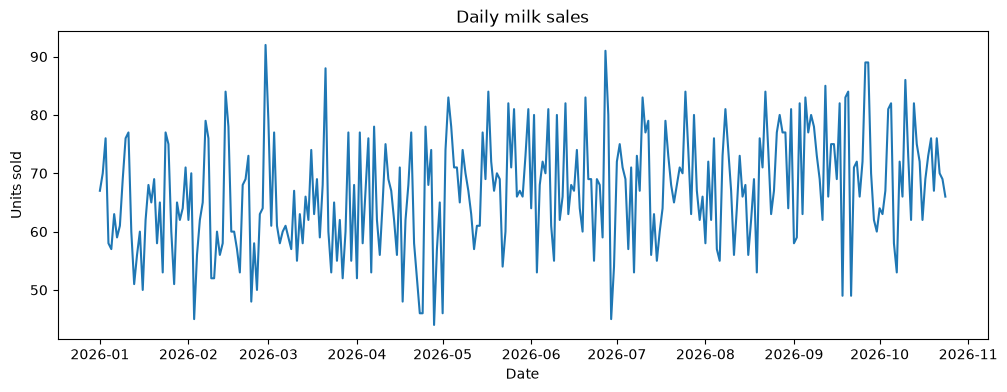

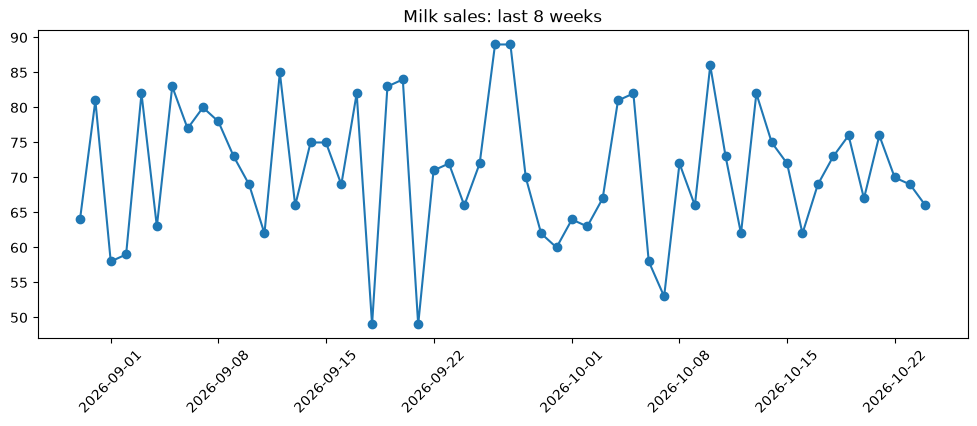

Data: (2376, 3) 2026-01-01 to 2026-10-24
Train rows: 2264 | Test rows: 112
Missing predictions: 0

Weekday baseline MAE: 5.56 units per item per day

Per-item summary:
          avg_sales  mae  bias  mae_pct_of_sales
item                                            
Bananas        32.4  4.3   1.8              13.3
Bread          52.9  7.9  -2.0              14.9
Curd           41.4  4.9  -2.5              11.8
Eggs           82.4  6.8   1.3               8.3
Milk           70.9  7.5   0.3              10.6
Paneer         22.4  2.9  -0.8              12.9
Samosa         50.2  6.1  -2.2              12.2
Tomatoes       37.8  4.1   2.5              10.8

Flat 28-day average MAE: 6.18


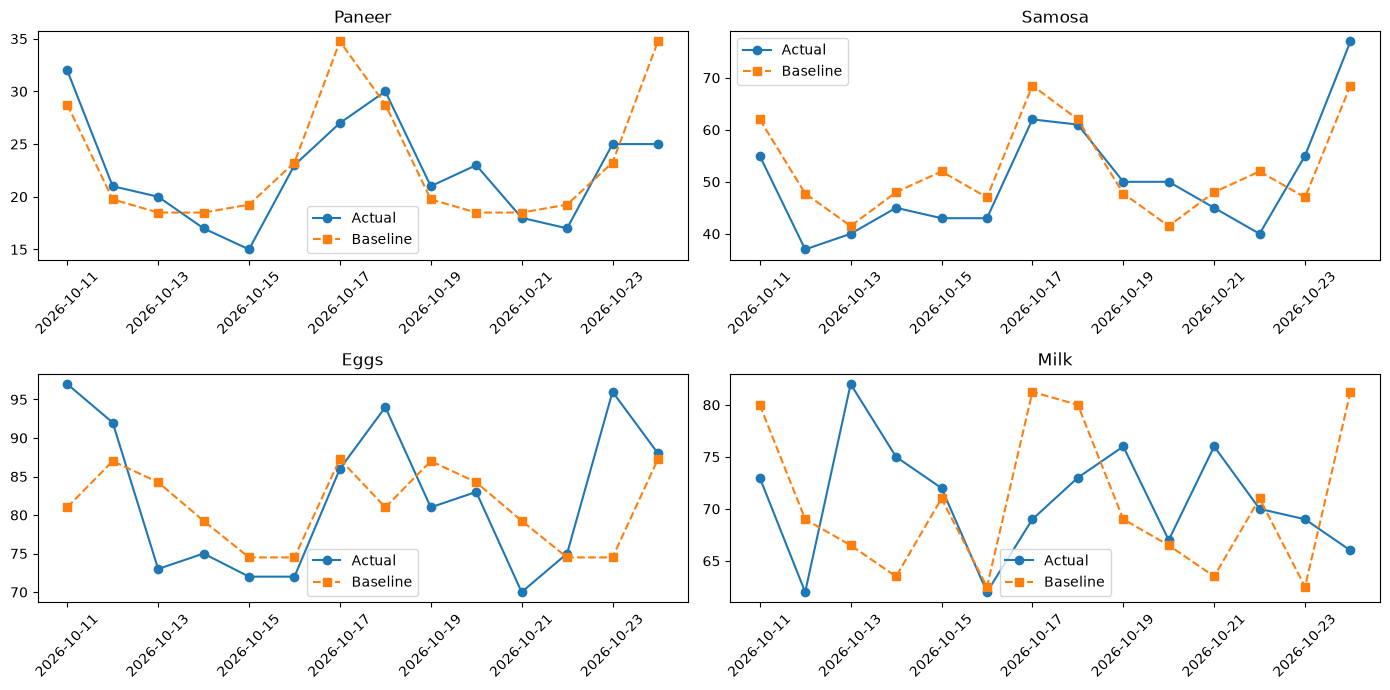


Saved baseline_results.csv and baseline_summary.csv
Using Prophet: True

Baseline MAE overall: 5.56
Model MAE overall:    5.39

Per item:
          avg_sales  baseline_mae  model_mae    better
item                                                  
Bananas       32.43          4.29       4.32  Baseline
Bread         52.86          7.93       6.96     Model
Curd          41.36          4.89       4.86     Model
Eggs          82.43          6.79       7.51  Baseline
Milk          70.86          7.46       6.33     Model
Paneer        22.43          2.93       2.99  Baseline
Samosa        50.21          6.07       5.99     Model
Tomatoes      37.79          4.11       4.13  Baseline


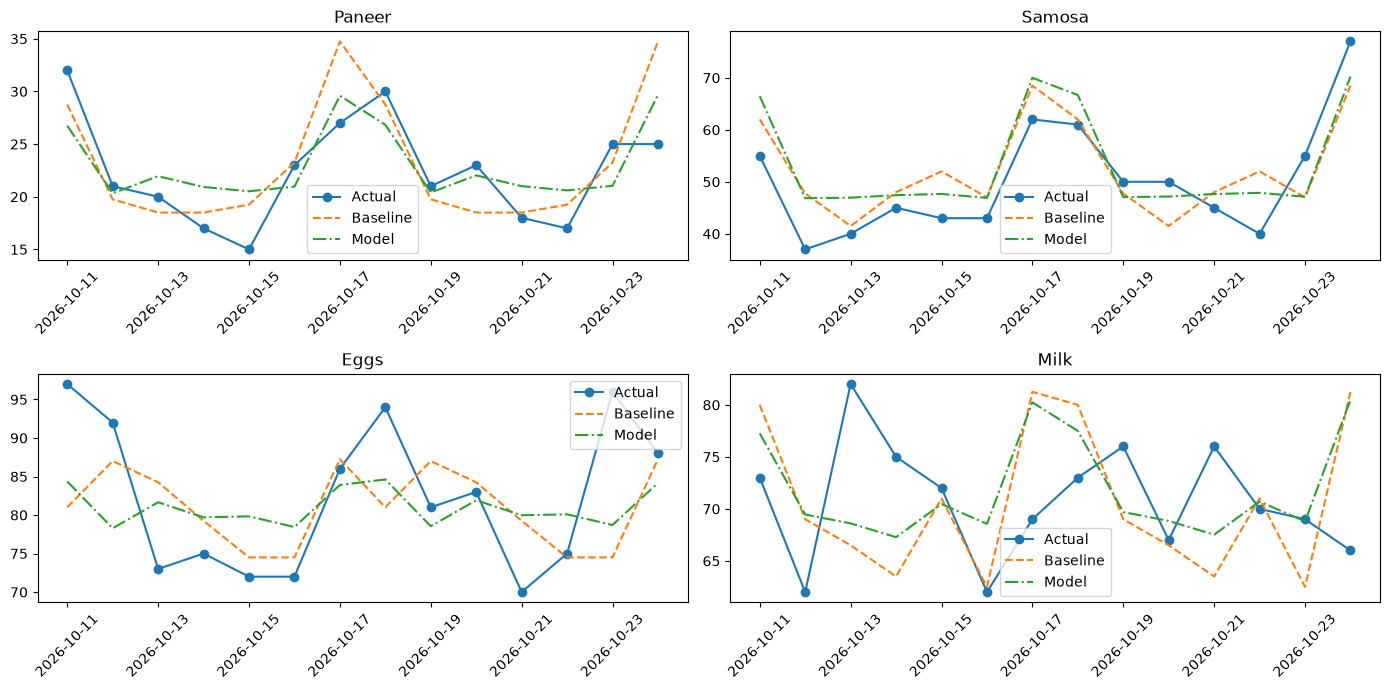


Forecast window: 2026-10-25 to 2026-11-07
Saved history.csv, forecast.csv, model_comparison.csv
=== Last 14 days, all items ===
policy            Forecast +10%  Gut feel (yesterday +20%)
ordered                  6086.0                     6609.0
sold                     5435.0                     5431.0
wasted                    119.0                      275.0
lost_sales                 30.0                       34.0
waste_cost                952.0                     3736.0
lost_profit               154.0                      256.0
profit                  39575.0                    36689.0
waste_pct                   2.0                        4.2
unmet_demand_pct            0.5                        0.6

=== Waste cost (Rs) by item ===
policy    Forecast +10%  Gut feel (yesterday +20%)
item                                              
Bananas               0                        168
Bread                 0                        480
Curd                  0                     

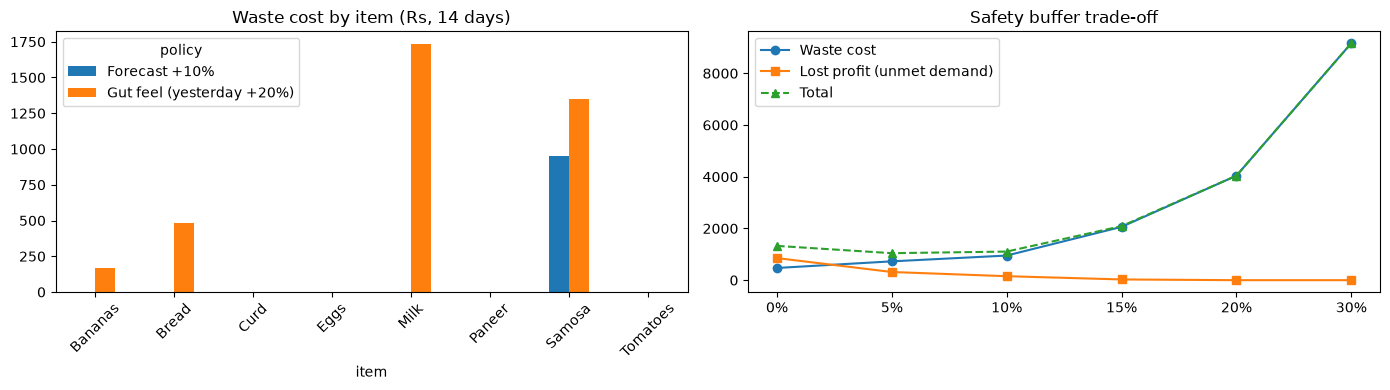


Saved waste_daily.csv, waste_by_policy.csv, buffer_sweep.csv


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

items = pd.DataFrame({
    "item":            ["Milk", "Bread", "Tomatoes", "Paneer", "Curd", "Bananas", "Eggs", "Samosa"],
    "base_demand":     [60,      45,      30,         18,       35,     25,        70,     40],
    "weekend_boost":   [1.15,    1.10,    1.25,       1.40,     1.10,   1.30,      1.05,   1.50],
    "shelf_life_days": [3,       3,       4,          5,        5,      3,         14,     1],
    "unit_cost":       [28,      30,      22,         90,       20,     6,         6,      8],
    "unit_price":      [34,      40,      30,         120,      28,     10,        8,      15],
})
items

rng = np.random.default_rng(42)          # fixed seed so we all get the same numbers
dates = pd.date_range("2026-01-01", "2026-10-24", freq="D")

records = []
for _, row in items.iterrows():
    for d in dates:
        weekend = row["weekend_boost"] if d.dayofweek >= 5 else 1.0
        trend = 1 + 0.0005 * (d - dates[0]).days     # slow growth over time
        expected = row["base_demand"] * weekend * trend
        qty = rng.poisson(expected)                   # random but realistic daily numbers
        records.append((d, row["item"], qty))

sales = pd.DataFrame(records, columns=["date", "item", "quantity_sold"])
sales.head(10)

sales.to_csv("../raw_data/sales.csv", index=False)
items.to_csv("../raw_data/items.csv", index=False)
print(sales.shape)

sales.info()
print(sales.isna().sum())
sales.describe()

milk = sales[sales["item"] == "Milk"]

plt.figure(figsize=(12, 4))
plt.plot(milk["date"], milk["quantity_sold"])
plt.title("Daily milk sales")
plt.xlabel("Date")
plt.ylabel("Units sold")
plt.show()

last8 = milk.tail(56)

plt.figure(figsize=(12, 4))
plt.plot(last8["date"], last8["quantity_sold"], marker="o")
plt.title("Milk sales: last 8 weeks")
plt.xticks(rotation=45)
plt.show()

sales["weekday"] = sales["date"].dt.day_name()
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

by_weekday = sales.pivot_table(index="item", columns="weekday",
                               values="quantity_sold", aggfunc="mean")[order].round(1)
by_weekday


import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- 0. Load data ----------
sales = pd.read_csv("../raw_data/sales.csv", parse_dates=["date"])
items = pd.read_csv("../raw_data/items.csv")
print("Data:", sales.shape, sales["date"].min().date(), "to", sales["date"].max().date())

# ---------- 1. Train / test split (by time) ----------
cutoff = sales["date"].max() - pd.Timedelta(days=14)
train = sales[sales["date"] <= cutoff].copy()
test = sales[sales["date"] > cutoff].copy()
print("Train rows:", len(train), "| Test rows:", len(test))

# ---------- 2. Baseline: average of same weekday, last 4 weeks ----------
train["weekday"] = train["date"].dt.dayofweek
test["weekday"] = test["date"].dt.dayofweek

last4 = train.sort_values("date").groupby(["item", "weekday"]).tail(4)
baseline = (
    last4.groupby(["item", "weekday"])["quantity_sold"]
    .mean().rename("predicted").reset_index()
)

result = test.merge(baseline, on=["item", "weekday"], how="left")
result["error"] = result["quantity_sold"] - result["predicted"]
result["abs_error"] = result["error"].abs()
print("Missing predictions:", result["predicted"].isna().sum())

# ---------- 3. Error measurement ----------
overall_mae = result["abs_error"].mean()
print("\nWeekday baseline MAE:", round(overall_mae, 2), "units per item per day")

summary = (
    result.groupby("item")
    .agg(avg_sales=("quantity_sold", "mean"),
         mae=("abs_error", "mean"),
         bias=("error", "mean"))
    .round(1)
)
summary["mae_pct_of_sales"] = (summary["mae"] / summary["avg_sales"] * 100).round(1)
print("\nPer-item summary:")
print(summary)

# ---------- 4. Dumber baseline: flat 28-day average ----------
flat = (
    train[train["date"] > cutoff - pd.Timedelta(days=28)]
    .groupby("item")["quantity_sold"].mean()
    .rename("flat_pred").reset_index()
)
check = result.merge(flat, on="item")
flat_mae = (check["quantity_sold"] - check["flat_pred"]).abs().mean()
print("\nFlat 28-day average MAE:", round(flat_mae, 2))

# ---------- 5. Plots: actual vs baseline for 4 items ----------
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for ax, name in zip(axes.flatten(), ["Paneer", "Samosa", "Eggs", "Milk"]):
    one = result[result["item"] == name].sort_values("date")
    ax.plot(one["date"], one["quantity_sold"], marker="o", label="Actual")
    ax.plot(one["date"], one["predicted"], marker="s", linestyle="--", label="Baseline")
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=45)
    ax.legend()
plt.tight_layout()
plt.show()

# ---------- 6. Save ----------
os.makedirs("../clean_data", exist_ok=True)
result[["date", "item", "quantity_sold", "predicted", "error", "abs_error"]].to_csv(
    "../clean_data/baseline_results.csv", index=False)
summary.to_csv("../clean_data/baseline_summary.csv")
print("\nSaved baseline_results.csv and baseline_summary.csv")


import os
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# ---------- 0. Load ----------
sales = pd.read_csv("../raw_data/sales.csv", parse_dates=["date"])
base = pd.read_csv("../clean_data/baseline_results.csv", parse_dates=["date"])

cutoff = sales["date"].max() - pd.Timedelta(days=14)
train = sales[sales["date"] <= cutoff].copy()
test = sales[sales["date"] > cutoff].copy()

# ---------- 1. Is Prophet available? ----------
try:
    from prophet import Prophet
    logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
    logging.getLogger("prophet").setLevel(logging.WARNING)
    USE_PROPHET = True
except ImportError:
    USE_PROPHET = False
print("Using Prophet:", USE_PROPHET)

# ---------- 2. One function that forecasts one item ----------
def forecast_item(history, periods=14):
    """history has columns: date, quantity_sold. Returns date, predicted, lower, upper."""
    if USE_PROPHET:
        df = history.rename(columns={"date": "ds", "quantity_sold": "y"})
        m = Prophet(weekly_seasonality=True, yearly_seasonality=False,
                    daily_seasonality=False, interval_width=0.8)
        m.fit(df)
        future = m.make_future_dataframe(periods=periods)
        fc = m.predict(future).tail(periods)
        return pd.DataFrame({"date": fc["ds"].values, "predicted": fc["yhat"].values,
                             "lower": fc["yhat_lower"].values, "upper": fc["yhat_upper"].values})
    # fallback: trend + weekday dummies
    d0 = history["date"].min()
    def features(dates):
        X = pd.get_dummies(pd.Series(dates).dt.dayofweek).reindex(columns=range(7), fill_value=0)
        X["trend"] = (pd.Series(dates) - d0).dt.days.values
        return X.astype(float)
    model = LinearRegression().fit(features(history["date"]), history["quantity_sold"])
    resid = history["quantity_sold"] - model.predict(features(history["date"]))
    future_dates = pd.date_range(history["date"].max() + pd.Timedelta(days=1), periods=periods)
    pred = model.predict(features(future_dates))
    return pd.DataFrame({"date": future_dates, "predicted": pred,
                         "lower": pred - 1.28 * resid.std(), "upper": pred + 1.28 * resid.std()})

# ---------- 3. Validation: fit on train, predict the 14 test days ----------
parts = []
for name, g in train.groupby("item"):
    fc = forecast_item(g[["date", "quantity_sold"]])
    fc["item"] = name
    parts.append(fc)
val = pd.concat(parts)
val["predicted"] = val["predicted"].clip(lower=0)

cmp = test.merge(val[["date", "item", "predicted"]], on=["date", "item"])
cmp = cmp.merge(base[["date", "item", "predicted"]].rename(columns={"predicted": "baseline_pred"}),
                on=["date", "item"])
cmp["model_err"] = (cmp["quantity_sold"] - cmp["predicted"]).abs()
cmp["base_err"] = (cmp["quantity_sold"] - cmp["baseline_pred"]).abs()

per_item = cmp.groupby("item").agg(avg_sales=("quantity_sold", "mean"),
                                   baseline_mae=("base_err", "mean"),
                                   model_mae=("model_err", "mean")).round(2)
per_item["better"] = np.where(per_item["model_mae"] < per_item["baseline_mae"], "Model", "Baseline")
print("\nBaseline MAE overall:", round(cmp["base_err"].mean(), 2))
print("Model MAE overall:   ", round(cmp["model_err"].mean(), 2))
print("\nPer item:")
print(per_item)

# ---------- 4. Plot 4 items ----------
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for ax, name in zip(axes.flatten(), ["Paneer", "Samosa", "Eggs", "Milk"]):
    one = cmp[cmp["item"] == name].sort_values("date")
    ax.plot(one["date"], one["quantity_sold"], marker="o", label="Actual")
    ax.plot(one["date"], one["baseline_pred"], linestyle="--", label="Baseline")
    ax.plot(one["date"], one["predicted"], linestyle="-.", label="Model")
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=45)
    ax.legend()
plt.tight_layout()
plt.show()

# ---------- 5. Final forecast: refit on ALL data, predict next 14 days ----------
parts = []
for name, g in sales.groupby("item"):
    fc = forecast_item(g[["date", "quantity_sold"]])
    fc["item"] = name
    parts.append(fc)
future = pd.concat(parts)
for col in ["predicted", "lower", "upper"]:
    future[col] = future[col].clip(lower=0)

# recommended order = forecast + 10% safety buffer, rounded up
future["recommended_order"] = np.ceil(future["predicted"] * 1.10).astype(int)
future[["predicted", "lower", "upper"]] = future[["predicted", "lower", "upper"]].round(1)
future = future[["item", "date", "predicted", "lower", "upper", "recommended_order"]]

# ---------- 6. Save ----------
os.makedirs("../clean_data", exist_ok=True)
sales.to_csv("../clean_data/history.csv", index=False)
future.to_csv("../clean_data/forecast.csv", index=False)
per_item.to_csv("../clean_data/model_comparison.csv")
print("\nForecast window:", future["date"].min().date(), "to", future["date"].max().date())
print("Saved history.csv, forecast.csv, model_comparison.csv")
future.head(10)


import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- 0. Load ----------
sales = pd.read_csv("../raw_data/sales.csv", parse_dates=["date"])
items = pd.read_csv("../raw_data/items.csv")
base = pd.read_csv("../clean_data/baseline_results.csv", parse_dates=["date"])
info = items.set_index("item")

# ---------- 1. Orders under different policies (last 14 days) ----------
test = base[["date", "item", "quantity_sold", "predicted"]].copy().sort_values(["item", "date"])
test = test.rename(columns={"quantity_sold": "demand", "predicted": "forecast"})

# "Gut feel": order what sold yesterday + 20%
daily = sales.sort_values(["item", "date"]).copy()
daily["yesterday"] = daily.groupby("item")["quantity_sold"].shift(1)
test = test.merge(daily[["date", "item", "yesterday"]], on=["date", "item"], how="left")

BUFFER = 0.10
orders = {
    "Gut feel (yesterday +20%)": np.ceil(test["yesterday"] * 1.20),
    "Forecast +10%": np.ceil(test["forecast"] * (1 + BUFFER)),
}

# ---------- 2. Shelf-life simulation ----------
def simulate(df, order_col, shelf_life):
    stock = []                       # list of [age_in_days, quantity]
    rows = []
    for _, r in df.iterrows():
        stock.append([0, int(r[order_col])])             # new delivery this morning
        need = int(r["demand"])
        sold = 0
        for batch in sorted(stock, key=lambda b: -b[0]):  # oldest first (FIFO)
            take = min(batch[1], need - sold)
            batch[1] -= take
            sold += take
        for b in stock:                                   # end of day: ageing
            b[0] += 1
        wasted = sum(b[1] for b in stock if b[0] >= shelf_life)
        stock = [b for b in stock if b[0] < shelf_life and b[1] > 0]
        rows.append((r["date"], r["item"], int(r[order_col]), need, sold, wasted, need - sold))
    return pd.DataFrame(rows, columns=["date", "item", "ordered", "demand", "sold", "wasted", "lost_sales"])

parts = []
for policy, ordered in orders.items():
    t = test.copy()
    t["order_qty"] = ordered.values
    for name, g in t.groupby("item"):
        out = simulate(g.sort_values("date"), "order_qty", int(info.loc[name, "shelf_life_days"]))
        out["policy"] = policy
        parts.append(out)
sim = pd.concat(parts, ignore_index=True)

# ---------- 3. Money ----------
sim["unit_cost"] = sim["item"].map(info["unit_cost"])
sim["unit_price"] = sim["item"].map(info["unit_price"])
sim["waste_cost"] = sim["wasted"] * sim["unit_cost"]
sim["lost_profit"] = sim["lost_sales"] * (sim["unit_price"] - sim["unit_cost"])
sim["revenue"] = sim["sold"] * sim["unit_price"]
sim["profit"] = sim["sold"] * (sim["unit_price"] - sim["unit_cost"]) - sim["waste_cost"]

# ---------- 4. Summaries ----------
by_policy = sim.groupby("policy").agg(
    ordered=("ordered", "sum"), sold=("sold", "sum"), wasted=("wasted", "sum"),
    lost_sales=("lost_sales", "sum"), waste_cost=("waste_cost", "sum"),
    lost_profit=("lost_profit", "sum"), profit=("profit", "sum")).round(0)
by_policy["waste_pct"] = (by_policy["wasted"] / by_policy["ordered"] * 100).round(1)
by_policy["unmet_demand_pct"] = (by_policy["lost_sales"] / (by_policy["sold"] + by_policy["lost_sales"]) * 100).round(1)
print("=== Last 14 days, all items ===")
print(by_policy.T)

by_item = sim.pivot_table(index="item", columns="policy", values="waste_cost", aggfunc="sum").round(0)
print("\n=== Waste cost (Rs) by item ===")
print(by_item)

# ---------- 5. Buffer sweep: how much safety stock is right? ----------
sweep_rows = []
for buf in [0.0, 0.05, 0.10, 0.15, 0.20, 0.30]:
    t = test.copy()
    t["order_qty"] = np.ceil(t["forecast"] * (1 + buf))
    ps = []
    for name, g in t.groupby("item"):
        ps.append(simulate(g.sort_values("date"), "order_qty", int(info.loc[name, "shelf_life_days"])))
    s = pd.concat(ps)
    s["wc"] = s["wasted"] * s["item"].map(info["unit_cost"])
    s["lp"] = s["lost_sales"] * (s["item"].map(info["unit_price"]) - s["item"].map(info["unit_cost"]))
    sweep_rows.append((f"{int(buf*100)}%", s["wc"].sum(), s["lp"].sum(), s["wc"].sum() + s["lp"].sum(),
                       s["lost_sales"].sum() / s["demand"].sum() * 100))
sweep = pd.DataFrame(sweep_rows, columns=["buffer", "waste_cost", "lost_profit", "total_loss", "unmet_demand_pct"]).round(1)
print("\n=== Buffer sweep ===")
print(sweep)

# ---------- 6. Chart ----------
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
by_item.plot(kind="bar", ax=ax[0]); ax[0].set_title("Waste cost by item (Rs, 14 days)"); ax[0].tick_params(axis="x", rotation=45)
ax[1].plot(sweep["buffer"], sweep["waste_cost"], marker="o", label="Waste cost")
ax[1].plot(sweep["buffer"], sweep["lost_profit"], marker="s", label="Lost profit (unmet demand)")
ax[1].plot(sweep["buffer"], sweep["total_loss"], marker="^", linestyle="--", label="Total")
ax[1].set_title("Safety buffer trade-off"); ax[1].legend()
plt.tight_layout()
plt.show()

# ---------- 7. Save for Power BI ----------
os.makedirs("../clean_data", exist_ok=True)
sim.to_csv("../clean_data/waste_daily.csv", index=False)
by_policy.to_csv("../clean_data/waste_by_policy.csv")
sweep.to_csv("../clean_data/buffer_sweep.csv", index=False)
print("\nSaved waste_daily.csv, waste_by_policy.csv, buffer_sweep.csv")
